# 2A.3 Zoekstrategieën

In dit deel gaan we verschillende strategieën ontdekken die gebruikt worden om algoritmes te bouwen. Er bestaan een hele reeks aan soorten algorithmes, oa.:
- Gulzige/greedy algoritmes
- Benaderingsalgoritmes
- Probabilistische algoritmes
- Iteratieve verbeteringsalgoritmes
- Verdeel-en-heers algoritmes (2B.1)
- Dynamisch programmeren (2B.1)
- Backtracking algoritmes (2B.2)

Buiten de laatste 3 algoritmes hebben de meeste van deze algoritmes een specifieke invulling per probleem. De laatste 3 bouwen op het principe van recursie dat meer algemeen toepasbaar is.

Hieronder worden de andere 4 nog kort even geschetst.

## Gulzige algoritmes

Een gulzig algoritme zal proberen om zo snel mogelijk tot een oplossing te komen door de 'grootste'/beste stap te zetten die het kan gegeven de huidige oplossing. Dat maakt dat het vaak snel een oplossing biedt maar dus meestal een globaal optimum mist.

Een simpel voorbeeld van een 'gulzig' algoritme is het kopen en verkopen van een bepaald aandeel. In de lijst `prijzen` wordt de prijs van een aandeel bijgehouden over tijd. Een gulzig algoritme zou telkens kopen als de prijs laag is en verkopen wanneer de prijs hoger is dan de aankoopprijs. Dit leidt uiteindelijk tot een snelle oplossing en winst, maar het globale optimum zou bv. eerder kopen aan 1 en verkopen aan 14.

Desalniettemin zijn gulzige algoritmes vaak een goede oplossing.

In [20]:
def max_opbrengst_greedy(prijzen_in: list) -> float:
    totale_opbrengst = 0
    
    for i in range(1, len(prijzen_in)):
        if prijzen_in[i] > prijzen_in[i - 1]:
            totale_opbrengst += prijzen_in[i] - prijzen_in[i - 1]
    return totale_opbrengst

prijzen = [5, 1, 10, 3, 12, 7, 14]
print("Totale winst:", max_opbrengst_greedy(prijzen))

Totale winst: 25


## Benaderingsalgoritmes

Benaderingsalgoritmes zijn meestal een gesimplifieerde versie van een meer complex exact algoritme dat de beste uitkomst geeft. Ze laten vaak bepaalde restricties vallen die het oplossen van het exacte probleem moeilijk en dus traag maken.

Als voorbeeld bekijken we het knapzakprobleem dat bestaat uit het besteden van een aantal items met een bepaalde kost gegeven een budget die de opbrengst van alle items die je met dat budget kan kopen optimaliseert.

De exacte oplossing van dit probleem wordt meestal gedaan via een integer linear programming/ILP-probleem. Echter, een makkelijke benadering van de optimale oplossing is door de knapzak te vullen met de hoogstrederende items tot het budget op is. Het laatste item zal dan deels kunnen opgenomen worden:

In [21]:
def fractionele_knapsack(investeringen: list, budget: int) -> float:
    # dit sorteert de investeringen naar gelang hun opbrengstratio
    # opbrengst/kost
    investeringen.sort(key=lambda x: x[2] / x[1], reverse=True)
    totale_opbrengst = 0
    
    for naam, kost, opbrengst in investeringen:
        print('Budget aan start:', budget)
        if budget >= kost:
            print(naam, 'past binnen budget')
            budget -= kost
            totale_opbrengst += opbrengst
        else:
            print(naam, 'past nog maar voor een fractie in het budget')
            totale_opbrengst += (budget / kost) * opbrengst
            break # moeten stoppen, want budget is op
    return totale_opbrengst

# de assets zijn tupels met een naam, kost en opbrengst
investeringen = [
    ("A", 20000, 18000),
    ("B", 30000, 25000),
    ("C", 10000, 7000),
    ("D", 25000, 20000)
]
budget = 55000
print("Totale verwachte opbrengst:", fractionele_knapsack(investeringen, budget))

Budget aan start: 55000
A past binnen budget
Budget aan start: 35000
B past binnen budget
Budget aan start: 5000
D past nog maar voor een fractie in het budget
Totale verwachte opbrengst: 47000.0


Dit is slechts een benadering van de optimale opbrengst en een oplossing die op zich niet mogelijk is indien investeringen niet in fracties kunnen aangekocht worden. Dit vormt wel een startoplossing waarmee we lokaal tot een oplossing kunnen komen: we hebben al A/B en een fractie van D. We kunnen dan bv. D weglaten of vervangen door iets wat wel nog binnen budget past.

## Probabilistische algoritmes

Veel algoritmes gebruiken kansrekenen om strategisch bepaalde trekkingen te doen uit een groot aantal van mogelijke oplossingen voor een probleem. Een veelgebruikte opzet hierbij is de Monte Carlo simulatie die gaat proberen een zo'n groot mogelijke coverage te bekomen van de oplossingen. Denk bijvoorbeeld aan een foto. Hoe meer pixels je random uit de foto begint te verzamelen, hoe beter jouw beeld wordt van de totale figuren en eigenschappen in de foto.

Hieronder wordt zo'n simulatie gebruikt om een financiële schatting te maken van een aandeel waarbij de parameters kunnen gebruikt worden om de impact van de dagelijkste opbrengst en volatiliteit over een jaar (verander `aantal_dagen` naar 252 om het aantal werkdagen per jaar te gebruiken) lang investeren te leren. 

Doordat we de uitkomst van verschillende willekeurige uitkomsten bekomen vinden we een stabiele weergave van de verdeling van de waardes die worden gegenereerd.

In [22]:
import numpy as np

def monte_carlo_simulatie(waarde_in, opbrengst_in, volatiliteit_in, dagen_in, aantal_simulaties=10):
    eind_waardes = []
    
    for s in range(aantal_simulaties):
        dagelijkse_opbrengst = np.random.normal(opbrengst_in, volatiliteit_in, aantal_dagen)
        print(f'Opbrengsten van simulatie {s}:', dagelijkse_opbrengst)
        # vermenigvuldig al de elementen uit dagelijkse_opbrengst met elkaar als rendement (+1)
        eind_waarde = waarde_in * np.prod(1 + dagelijkse_opbrengst)
        eind_waardes.append(eind_waarde)
        print()
        
    return eind_waardes

# parameters van onze simulatie
start_waarde = 100000  
dagelijkste_opbrengst = 0.0005  
dagelijkste_volatiliteit = 0.01 
aantal_dagen = 15

# zet de willekeurige getallen vast
np.random.seed(42) 
eind_waardes = monte_carlo_simulatie(start_waarde, dagelijkste_opbrengst, dagelijkste_volatiliteit, aantal_dagen)

gemiddelde_eindopbrengst = np.mean(eind_waardes)
print(f"Verwachte opbrengst na {aantal_dagen} dagen:", gemiddelde_eindopbrengst)

Opbrengsten van simulatie 0: [ 0.00546714 -0.00088264  0.00697689  0.0157303  -0.00184153 -0.00184137
  0.01629213  0.00817435 -0.00419474  0.0059256  -0.00413418 -0.0041573
  0.00291962 -0.0186328  -0.01674918]

Opbrengsten van simulatie 1: [-0.00512288 -0.00962831  0.00364247 -0.00858024 -0.01362304  0.01515649
 -0.00175776  0.00117528 -0.01374748 -0.00494383  0.00160923 -0.01100994
  0.00425698 -0.00550639 -0.00241694]

Opbrengsten van simulatie 2: [-0.00551707  0.01902278  0.00036503 -0.01007711  0.00872545 -0.01170844
  0.00258864 -0.0190967  -0.01278186  0.00246861  0.00788467  0.00221368
 -0.00065648 -0.00251104 -0.01428522]

Opbrengsten van simulatie 3: [-0.00669844 -0.00410639  0.01107122  0.00393618 -0.0171304   0.00374084
 -0.00335082 -0.00626922  0.00661676  0.01081     0.0098128  -0.00789218
 -0.00259212  0.00381263  0.01025545]

Opbrengsten van simulatie 4: [-0.00429174 -0.00135659 -0.01056335 -0.01146207  0.00862526  0.0140624
 -0.0002201   0.01053533  0.00411636 -0.0059

## Iteratieve verbeteringsalgoritmes

Het probleem met benaderings- en gulzige algoritmes is dat ze vaak vastraken in een lokaal optimum. Een andere familie van algoritmes die dit probeert te overkomen zijn de iteratieve verbeteringsalgoritmes (lokale zoek/local search algoritmes).
Ze zullen, volgens een bepaald patroon zoals bv. om een aantal zoekstappen, de zoekomgeving verlaten en naar een totaal andere plaats in de zoekruimte springen. Zo zorgen ze ervoor dat de kans verhoogt dat andere optima niet gemist worden.

Hieronder wordt een voorbeeld uitgewerkt waarbij een zoek-algoritme verspringt als er lokaal geen verbetering meer te vinden is.
Er wordt een lijst van prijzen gegeven, bv. aandeelprijzen over tijd, waarbij het grootste verschil tussen de koop- en verkoop-periode wordt gezocht. Als er geen verbetering is door op de huidige posities `koop` en `verkoop` lokaal te zoeken, wordt de lokale oplossing als optimaal beschouwd. Door dit verschillende keren te herhalen over verschillende buurten treden er vaak betere globale oplossingen op.

In [ ]:
def lokale_zoeker(prijzen: list, koop: int, verkoop: int) -> tuple:
    print('Start: koop op', koop, 'verkoop op', verkoop)
    winst = prijzen[verkoop] - prijzen[koop]
    print('Startwinst:', winst)
    verbeterd = True
    while verbeterd:                        # zolang een buur beter is
        verbeterd = False
        print('Koop:', koop, 'verkoop:', verkoop, 'winst:', winst)
        for dk, dv in [(-1, 0), (1, 0), (0, -1), (0, 1)]:       # de vier buren van (koop, verkoop), links van koop, rechts van koop, links van verkoop, rechts van verkoop
            k, v = koop + dk, verkoop + dv
            if 0 <= k < v < len(prijzen):
                print(k, v, 'winst:', prijzen[v] - prijzen[k])
                if prijzen[v] - prijzen[k] > winst:
                    print('Betere winst')
                    koop, verkoop, winst = k, v, prijzen[v] - prijzen[k]
                    verbeterd = True             # ga naar de betere buur
    return koop, verkoop, winst
 
prijzen = [5, 1, 10, 3, 12, 7, 14]
print(lokale_zoeker(prijzen, 0, 1))     # (1, 2, 9)   lokaal optimum
print(lokale_zoeker(prijzen, 0, 6))     # (1, 6, 13)  globaal optimum

Start: koop op 0 verkoop op 1
Startwinst: -4
Koop: 0 verkoop: 1 winst: -4
0 2 winst: 5
Betere winst
Koop: 0 verkoop: 2 winst: 5
1 2 winst: 9
Betere winst
1 3 winst: 2
Koop: 1 verkoop: 2 winst: 9
0 2 winst: 5
1 3 winst: 2
(1, 2, 9)
Start: koop op 0 verkoop op 6
Startwinst: 9
Koop: 0 verkoop: 6 winst: 9
1 6 winst: 13
Betere winst
1 5 winst: 6
Koop: 1 verkoop: 6 winst: 13
0 6 winst: 9
2 6 winst: 4
1 5 winst: 6
(1, 6, 13)


Een ander voorbeeld waarvoor we terug de marketing dataset genereren:

In [25]:
import pandas as pd
import numpy as np

np.random.seed(42)

n_klanten = 100

klant_ids = np.arange(1, n_klanten + 1)
leeftijden = np.random.randint(18, 70, size=n_klanten)
maandelijkse_uitgaven = np.round(np.random.uniform(50, 1000, size=n_klanten), 2)

# Score van 1 tot 10
loyaliteitsscore = np.random.randint(1, 11, size=n_klanten)  

klant_data = pd.DataFrame({
    "Klant_ID": klant_ids,
    "Leeftijd": leeftijden,
    "Maandelijkse_Uitgaven": maandelijkse_uitgaven,
    "Loyaliteitsscore": loyaliteitsscore
})

klant_data.head()

,Klant_ID,Leeftijd,Maandelijkse_Uitgaven,Loyaliteitsscore
0,1,56,207.00,3
1,2,69,64.85,4
2,3,46,452.23,4
3,4,32,425.14,3
4,5,60,328.81,10


We berekenen 2 soorten winsten na het implementeren van een nieuwe online ad-strategie waarbij 'Google Ads' in een bepaalde ratio wordt aangeboden (i.e. hoeveel % van ons budget naar Google Ads gaat vs. de rest):

- `winst_kosten` reflecteert dat er een marge is aan de opbrengsten die samenhangen met de maandelijkste uitgaven. Er zijn ook vaste kosten.
- `winst_geen_kosten` voorziet een scenario waarbij er geen vaste kosten zijn en er enkel bepaalde klanten zullen reageren op de ad, gelinkst aan hun loyaliteitsscore.

ad                       0.50
winst_kosten          5284.86
winst_geen_kosten    39090.77
Name: 5, dtype: float64
ad                       0.600
winst_kosten          5262.272
winst_geen_kosten    49675.810
Name: 6, dtype: float64


<Axes: >

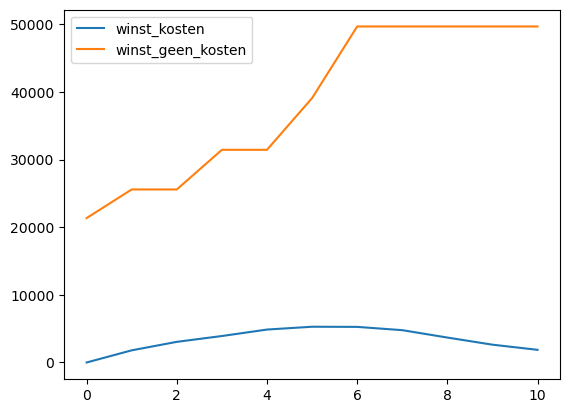

In [ ]:
def winst(google_ad, marge=0.4, kosten=180):
    # klanten die veel uitgeven 
    doel = klant_data[klant_data['Maandelijkse_Uitgaven'] > 1000 * (1 - google_ad)]
    # marge van de uitgaven - kosten over alle doel-klanten
    return (marge * doel['Maandelijkse_Uitgaven'] - kosten).sum()

ad_winst = {'ad':[], 'winst_kosten':[], 'winst_geen_kosten':[]}

# we genereren verschillende scenario's waarin we de ratio ad-uitgaven voor Google Ads laten varieren
for google_ad in np.linspace(0, 1, 11):    
    ad_winst['ad'].append(google_ad)
    ad_winst['winst_kosten'].append(winst(google_ad))

    # loyale klanten zullen geen Google Ads krijgen, de minst loyale klanten wel
    filter_2 = klant_data[(klant_data['Loyaliteitsscore'] > (1-google_ad) * 5) | (klant_data['Loyaliteitsscore'] < google_ad * 2)]
    ad_winst['winst_geen_kosten'].append(filter_2['Maandelijkse_Uitgaven'].sum())

df = pd.DataFrame(ad_winst)
print(df.iloc[df['winst_kosten'].argmax()])
print(df.iloc[df['winst_geen_kosten'].argmax()])
df[['winst_kosten', 'winst_geen_kosten']].plot()

In [118]:
df

,ad,winst_kosten,winst_geen_kosten
0,0.0,0.000,21352.77
1,0.1,1796.156,25580.83
2,0.2,3051.060,25580.83
3,0.3,3912.376,31442.06
4,0.4,4867.524,31442.06
5,0.5,5284.860,39090.77
6,0.6,5262.272,49675.81
7,0.7,4777.260,49675.81
8,0.8,3684.164,49675.81
9,0.9,2630.912,49675.81


Nu zoeken we lokaal, in een regio -0.1 en 0.1 rond de huidige 'ad' waarde naar een nieuwe winst-verdeling. Door de vorm van de winst-variabelen zullen we ofwel op een plateau eindigen, ofwel hopelijk naar de top zoeken bij de `winst_kosten`-variabele:

In [ ]:
def zoek_beste_ad_ratio(data, ad_verdeling, winst_kolom):

    print('Ad-verdeling:', ad_verdeling)
    regio_is_beter = True
    beste_ad_waarde = ad_verdeling
    while regio_is_beter:
        print('\n\nHuidige beste ad verdeling:', beste_ad_waarde)
        huidige_winst = data[data['ad'] == beste_ad_waarde][winst_kolom].values[0]
        print('Huidige winst:', huidige_winst)

        # de beste winst in deze iteratie
        beste_winst = 0

        for richting in [-0.1, 0.1]:
            # print('Richting:', richting)

            # hier zitten we weer met het afrondingsprobleem van Python
            waarde = np.round(beste_ad_waarde - richting, 2)
            filter = data[abs(data['ad'] - waarde) < 0.01]

            # we halen de waarde en winst op de lijn die overeenkomt met de nieuwe
            # ad-waarde in de DataFrame data
            winst = filter[winst_kolom].values[0]
            waarde = filter['ad'].values[0]
            # print(filter)
            if winst > huidige_winst:
                print(f"Betere winst {winst} voor {waarde}")
                beste_winst = winst
                beste_ad_waarde = waarde
        regio_is_beter = False

        # als deze regio beter is blijven we hier zoeken
        if beste_winst > huidige_winst:
            regio_is_beter = True

    print(f'Beste ad-waarde voor {winst_kolom}:', beste_ad_waarde)
    return beste_ad_waarde

# deze code laat toe om te wisselen van winst-kolom door deze mee te geven als argument
# deze kolom kan dan automatisch opgevraagd worden in de DataFrame df waar nodig
winst = zoek_beste_ad_ratio(df, df['ad'].values[2], 'winst_kosten')
print('---')
# als je de start-waarde aanpast kan je in een betere startregio terechtkomen
winst = zoek_beste_ad_ratio(df, df['ad'].values[2], 'winst_geen_kosten')

Ad-verdeling: 0.2


Huidige ad verdeling: 0.2
Huidige winst: 3051.06
Betere winst 3912.376 voor 0.30000000000000004


Huidige ad verdeling: 0.30000000000000004
Huidige winst: 3912.376
Betere winst 4867.524 voor 0.4


Huidige ad verdeling: 0.4
Huidige winst: 4867.524
Betere winst 5284.8600000000015 voor 0.5


Huidige ad verdeling: 0.5
Huidige winst: 5284.8600000000015
Beste ad-waarde voor winst_kosten: 0.5
---
Ad-verdeling: 0.2


Huidige ad verdeling: 0.2
Huidige winst: 25580.83
Betere winst 31442.06 voor 0.30000000000000004


Huidige ad verdeling: 0.30000000000000004
Huidige winst: 31442.06
Beste ad-waarde voor winst_geen_kosten: 0.30000000000000004
